# Start point vs. the localised walk

Plots `geo_first_point.json` (the surveyed start point) and the camera
positions in `images_full.json` on top of the structure's `floormap.png`.

All three live in different files but the same **target frame** — UTM metres
where the structure carries a `design_tm`, paper inches where it does not — so
the only conversion needed is *target → paper → pixel*.

In [34]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

REPO = Path("/home/raghava.m/alignment")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from align.io.paths import case_paths, all_reality_ids
from align.frames import SheetGeometry, load_design_tm, target_to_paper

Image.MAX_IMAGE_PIXELS = None          # floormaps run to 6300 x 4500 and beyond

In [35]:
REALITY_ID = "RLT1788209853606"

p = case_paths(REALITY_ID)
for k, v in p.as_dict().items():
    print(f"{k:22s} {v}")

reality_id             RLT1788209853606
capture_id             CAP5X5XKDIEXLPCtAim
structure_id           STR1782967237745
root                   data
floorplan              /home/raghava.m/alignment/data/STR1782967237745/floormap.png
cloud                  /home/raghava.m/alignment/data/STR1782967237745/CAP5X5XKDIEXLPCtAim/RLT1788209853606/point_cloud.ply
tm                     /home/raghava.m/alignment/data/STR1782967237745/CAP5X5XKDIEXLPCtAim/RLT1788209853606/tm.json
images_full            /home/raghava.m/alignment/data/STR1782967237745/CAP5X5XKDIEXLPCtAim/RLT1788209853606/images_full.json
start_point            /home/raghava.m/alignment/data/STR1782967237745/CAP5X5XKDIEXLPCtAim/geo_first_point.json
design_tm              None
shots                  /home/raghava.m/alignment/data/STR1782967237745/CAP5X5XKDIEXLPCtAim/RLT1788209853606/shots.geojson
images_prod            /home/raghava.m/alignment/data/STR1782967237745/CAP5X5XKDIEXLPCtAim/RLT1788209853606/images.json
structure_dir     

## Loading

`case_points` does the frame work and returns everything in one place: camera
positions in the target frame, the same positions in paper inches and in
floormap pixels, and the start point in all three.

Two things it will not paper over:

* a capture's `geo_first_point.json` anchors **one** split — 60 of 132 — so when
  its `source_reality_id` names a sibling, `start_is_ours` is `False` and the
  marker is drawn hollow rather than silently attributed to this walk;
* `images_full.json` is ground truth, not an input. This notebook is analysis,
  so that is fine, but nothing here may be imported by the solver.

In [36]:
def case_points(reality_id):
    """Camera positions and the surveyed start point, in target / paper / pixel."""
    p = case_paths(reality_id)

    with Image.open(p.floorplan) as im:
        img_w, img_h = im.size
    geom = SheetGeometry(p.paper_w, p.paper_h, img_w, img_h)
    geom.check()                       # fails loudly if the aspect ratio disagrees

    design_tm = load_design_tm(p.design_tm) if p.design_tm else None
    to_px = lambda xyz: geom.paper_to_pixel(target_to_paper(np.atleast_2d(xyz),
                                                            design_tm)[:, :2])

    raw = json.loads(p.images_full.read_text())
    names = sorted(raw, key=lambda n: int(n.split("IMG_")[-1].split(".")[0])
                   if "IMG_" in n else -1)
    pos = np.array([raw[n]["position"] for n in names], dtype=float)

    start = start_px = start_name = None
    if p.start_point:
        j = json.loads(p.start_point.read_text())
        start = np.array([j["x"], j["y"], j["z"]], dtype=float)
        start_px = to_px(start)[0]
        start_name = j["image"]

    # the image the start point claims to be, so the gap is measured against the
    # right camera rather than whichever one happens to sort first
    anchor = names.index(start_name) if start_name in names else 0

    return dict(
        paths=p, geom=geom, design_tm=design_tm, names=names,
        pos=pos, pos_px=to_px(pos),
        start=start, start_px=start_px, start_name=start_name,
        anchor=anchor, anchor_px=to_px(pos[anchor])[0],
        start_is_ours=p.start_point_is_ours,
        units="m" if design_tm is not None else "in",
        gap=float(np.linalg.norm(start[:2] - pos[anchor][:2]))
            if start is not None else None,
        gap_px=float(np.linalg.norm(start_px - to_px(pos[anchor])[0]))
            if start is not None else None,
    )


d = case_points(REALITY_ID)
print(f"{len(d['names'])} cameras | frame = {'UTM metres' if d['design_tm'] is not None else 'paper inches'}"
      f" | {d['geom'].ppi:.1f} ppi")
print(f"start point {d['start_name']} -> anchors this split: {d['start_is_ours']}")
print(f"start to camera {d['anchor']}: {d['gap']:.2f} {d['units']}  =  {d['gap_px']:.0f} px")

330 cameras | frame = paper inches | 150.0 ppi
start point VID_20260831_121906_00_066_IMG_00001.JPG -> anchors this split: True
start to camera 0: 0.94 in  =  141 px


## Plotting

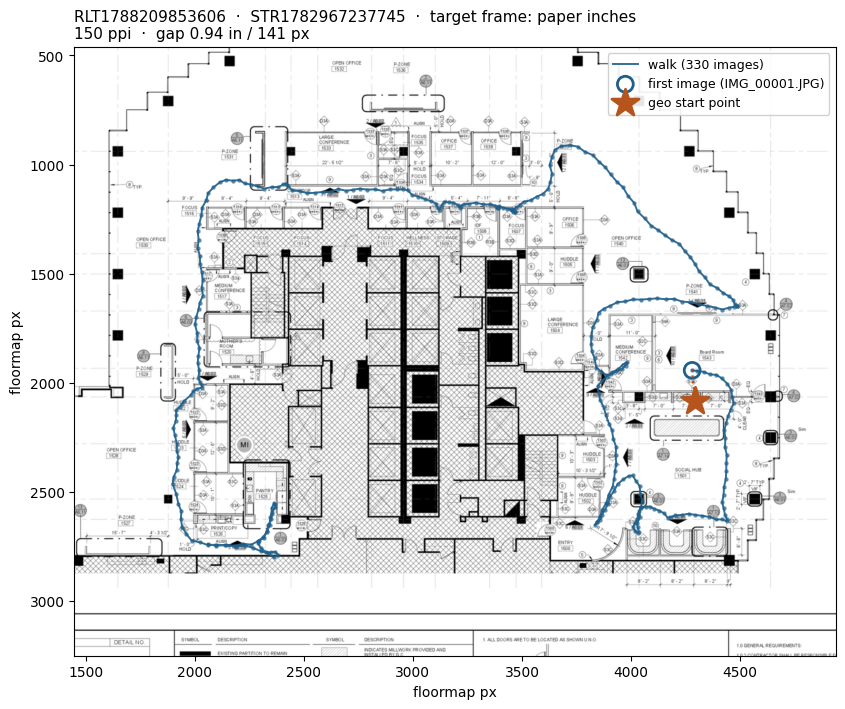

In [37]:
def plot_start_point(reality_id, crop=True, pad_in=3.0, max_px=1600,
                     ax=None, save=None):
    """Draw the walk and the surveyed start point on the structure's floormap.

    crop    -- zoom to the walk (plus `pad_in` inches of sheet); False shows the
               whole sheet, which is where you see if the capture landed on the
               wrong viewport
    max_px  -- downsample the crop for display only; every coordinate stays in
               full-resolution pixel space
    """
    d = case_points(reality_id)
    p, walk = d["paths"], d["pos_px"]

    pts = walk if d["start_px"] is None else np.vstack([walk, d["start_px"]])
    if crop:
        pad = pad_in * d["geom"].ppi
        x0, y0 = np.floor(pts.min(0) - pad).astype(int)
        x1, y1 = np.ceil(pts.max(0) + pad).astype(int)
        x0, y0 = max(x0, 0), max(y0, 0)
        x1 = min(x1, d["geom"].img_w); y1 = min(y1, d["geom"].img_h)
    else:
        x0, y0, x1, y1 = 0, 0, d["geom"].img_w, d["geom"].img_h

    with Image.open(p.floorplan) as im:
        sheet = im.convert("L").crop((x0, y0, x1, y1))
    scale = min(1.0, max_px / max(sheet.size))
    if scale < 1.0:
        sheet = sheet.resize((max(int(sheet.width * scale), 1),
                              max(int(sheet.height * scale), 1)), Image.LANCZOS)

    if ax is None:
        h = 9 * (y1 - y0) / max(x1 - x0, 1)
        _, ax = plt.subplots(figsize=(9, min(max(h, 3), 12)))
    # extent keeps the axes in full-resolution floormap pixels, y running down
    ax.imshow(sheet, cmap="gray", vmin=0, vmax=255, extent=(x0, x1, y1, y0),
              interpolation="bilinear", zorder=0)

    ax.plot(walk[:, 0], walk[:, 1], "-", color="#1f5f8b", lw=1.4, alpha=.9,
            zorder=2, label=f"walk ({len(walk)} images)")
    ax.scatter(walk[:, 0], walk[:, 1], s=5, color="#1f5f8b", alpha=.55, zorder=3)
    ax.scatter(*walk[d["anchor"]], s=130, facecolors="none", edgecolors="#1f5f8b",
               lw=2.0, zorder=4, label=f"first image ({d['names'][d['anchor']][-13:]})")

    if d["start_px"] is not None:
        owned = d["start_is_ours"]
        ax.scatter(*d["start_px"], marker="*", s=420, zorder=5,
                   color="#b5541d" if owned else "none",
                   edgecolors="#b5541d", linewidths=2.0,
                   label="geo start point" + ("" if owned else " (anchors a SIBLING split)"))
        ax.plot([d["start_px"][0], walk[d["anchor"], 0]],
                [d["start_px"][1], walk[d["anchor"], 1]],
                ":", color="#b5541d", lw=1.6, zorder=4)
        gap = f"gap {d['gap']:.2f} {d['units']} / {d['gap_px']:.0f} px"
    else:
        gap = "no geo start point on disk"

    frame = "UTM metres" if d["design_tm"] is not None else "paper inches"
    ax.set_title(f"{reality_id}  ·  {p.structure_id}  ·  target frame: {frame}\n"
                 f"{d['geom'].ppi:.0f} ppi  ·  {gap}", fontsize=11, loc="left")
    ax.set_xlabel("floormap px");  ax.set_ylabel("floormap px")
    ax.legend(loc="best", fontsize=9, framealpha=.9)
    ax.figure.tight_layout()
    if save:
        ax.figure.savefig(save, dpi=150, bbox_inches="tight")
        print("->", save)
    return ax


plot_start_point(REALITY_ID);

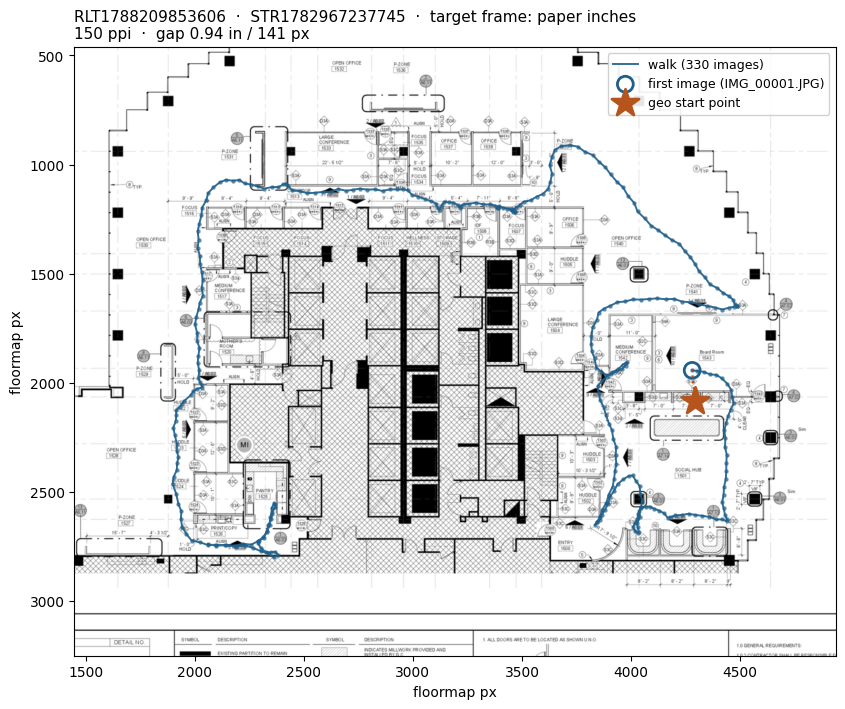

In [38]:
# the whole sheet, to check the capture landed on the right viewport
#REALITY_ID = "RLT1788173473510"
plot_start_point(REALITY_ID, crop=True);

## Sweep

Which splits actually own a start point, and how far it sits from the camera it
names.

In [29]:
rows = []
for rid in all_reality_ids():
    try:
        q = case_paths(rid)
        if not q.start_point_is_ours:
            continue
        d = case_points(rid)
        rows.append((rid, q.structure_id, d["units"], d["gap"], d["gap_px"]))
    except Exception as exc:
        print(f"{rid}: {exc!r}")

print(f"\n{len(rows)} splits own their capture's geo_first_point.json\n")
print(f"{'reality_id':22s} {'structure':20s} {'gap':>10s} {'px':>8s}")
for rid, sid, unit, gap, gap_px in sorted(rows, key=lambda r: -r[4]):
    print(f"{rid:22s} {sid:20s} {gap:7.2f} {unit:2s} {gap_px:8.0f}")


60 splits own their capture's geo_first_point.json

reality_id             structure                   gap       px
RLT1788201055417       STRNP423t7urx7q        33.70 in     5055
RLT1788572119536       STR1782849228036        7.80 in     4678
RLT1788551307044       STRvuIS9WNqmXft         6.38 in     1915
RLT1788588683827       STRvuIS9WNqmXft         6.35 in     1904
RLT1788566256285       STRmuHuDS7rr1Vf        40.28 m      1861
RLT1788630679597       STR1781782158035       12.22 in     1833
RLT1788593596573       STR4MNRcrElrQDW         8.83 in     1766
RLT1788555255826       STRvuIS9WNqmXft         5.59 in     1678
RLT1788654914263       STRQT5r86nbwgzk        35.12 m      1622
RLT1788488359558       STRCKW3wBavH1nq        18.91 m      1551
RLT1788551207003       STRvuIS9WNqmXft         5.14 in     1541
RLT1788551928459       STRGKUx1wpJanzZ        24.84 m      1522
RLT1788551604197       STRvuIS9WNqmXft         4.80 in     1441
RLT1788719765981       STR1782849228036        1.99

In [30]:
import pandas as pd

metadata = pd.concat([pd.read_csv(REPO / "dataset_28_local.csv"),
                      pd.read_csv(REPO / "dataset_105_local.csv")],
                     ignore_index=True)
metadata.head()

,reality_id,capture_id,project_id,structure_id,panovggt_point_cloud_path,design_floor_plan_path,shots_path,tm_path,images_prod_path,images_full_path,geo_path,"residue images, images_full",design_tm,design_tm_status,paper_width,paper_height,localisation_status,localisation tpr@1m
0,RLT1788195772679,CAP5FDjJAIuHHmSAjcB,PRJ999662,STReMnIXvisa5Lm,/home/raghava.m/alignment/data/STReMnIXvisa5Lm...,/home/raghava.m/alignment/data/STReMnIXvisa5Lm...,/home/raghava.m/alignment/data/STReMnIXvisa5Lm...,/home/raghava.m/alignment/data/STReMnIXvisa5Lm...,/home/raghava.m/alignment/data/STReMnIXvisa5Lm...,/home/raghava.m/alignment/data/STReMnIXvisa5Lm...,/home/raghava.m/alignment/data/STReMnIXvisa5Lm...,0.000000e+00,/home/raghava.m/alignment/data/STReMnIXvisa5Lm...,ok,36.000000,24.0,NaN,NaN
1,RLT1788186006235,CAP5H8ZQsErMkve1uQZ,PRJ835826,STR21ZxMOprBISb,/home/raghava.m/alignment/data/STR21ZxMOprBISb...,/home/raghava.m/alignment/data/STR21ZxMOprBISb...,/home/raghava.m/alignment/data/STR21ZxMOprBISb...,/home/raghava.m/alignment/data/STR21ZxMOprBISb...,/home/raghava.m/alignment/data/STR21ZxMOprBISb...,/home/raghava.m/alignment/data/STR21ZxMOprBISb...,/home/raghava.m/alignment/data/STR21ZxMOprBISb...,0.000000e+00,/home/raghava.m/alignment/data/STR21ZxMOprBISb...,ok,48.000000,36.0,NaN,NaN
2,RLT1788173473510,CAPvGJxCuO8y9waRAAO,PRJ406931,STRiuebZPxJnl0m,/home/raghava.m/alignment/data/STRiuebZPxJnl0m...,/home/raghava.m/alignment/data/STRiuebZPxJnl0m...,/home/raghava.m/alignment/data/STRiuebZPxJnl0m...,/home/raghava.m/alignment/data/STRiuebZPxJnl0m...,/home/raghava.m/alignment/data/STRiuebZPxJnl0m...,/home/raghava.m/alignment/data/STRiuebZPxJnl0m...,/home/raghava.m/alignment/data/STRiuebZPxJnl0m...,0.000000e+00,/home/raghava.m/alignment/data/STRiuebZPxJnl0m...,ok,48.003333,36.0,NaN,NaN
3,RLT1788209853606,CAP5X5XKDIEXLPCtAim,PRJ231822,STR1782967237745,/home/raghava.m/alignment/data/STR178296723774...,/home/raghava.m/alignment/data/STR178296723774...,/home/raghava.m/alignment/data/STR178296723774...,/home/raghava.m/alignment/data/STR178296723774...,/home/raghava.m/alignment/data/STR178296723774...,/home/raghava.m/alignment/data/STR178296723774...,/home/raghava.m/alignment/data/STR178296723774...,8.955363e-14,NaN,no_world_transform,42.003333,30.0,NaN,NaN
4,RLT1788200313009,CAP6ck6q0z2bDPg5gIg,PRJ062855,STR1747767829708,/home/raghava.m/alignment/data/STR174776782970...,/home/raghava.m/alignment/data/STR174776782970...,/home/raghava.m/alignment/data/STR174776782970...,/home/raghava.m/alignment/data/STR174776782970...,/home/raghava.m/alignment/data/STR174776782970...,/home/raghava.m/alignment/data/STR174776782970...,/home/raghava.m/alignment/data/STR174776782970...,0.000000e+00,/home/raghava.m/alignment/data/STR174776782970...,ok,42.000000,30.0,NaN,NaN
